In [1]:
import numpy as np
import matplotlib.pyplot as plt

import fig_settings as fs

fs.set_colors()
fs.set_fonts()

In [2]:
# Parameters
k = 10.0
gamma = 1.0
omega = 0.1
beta1 = 0.05
beta2 = 0.25

In [3]:
# Compute block-effective infectivities
b1 = (1 - omega) * beta1 + omega * beta2
b2 = (1 - omega) * beta2 + omega * beta1

# Parameter ranges
delta = np.linspace(-1, 1, 201)
epsilon = np.linspace(0, 1, 201)

D, E = np.meshgrid(delta, epsilon)

# R0 computation
trace = (1 + E) * ((1 + D) * b1 + (1 - D) * b2)

discriminant = (
    (1 + E)**2 * ((1 + D) * b1 - (1 - D) * beta2)**2
    + 4 * (1 - E)**2 * b1 * b2
)

R0 = (k / (2 * gamma)) * (trace + np.sqrt(discriminant))

<Figure size 325x305 with 0 Axes>

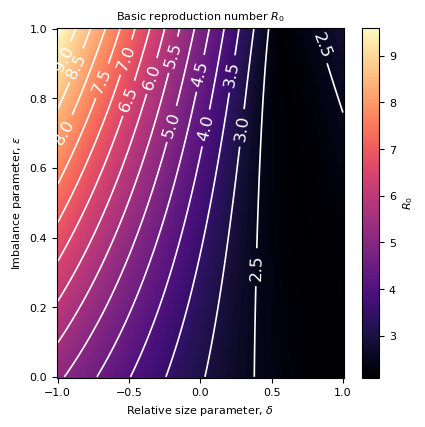

In [5]:
PANEL_W = 2.85   # width  of panel in inches
PANEL_H = 2.85    # height of panel

VSPACE    = 0.2   # vertical gap between panels (in inches)
LMARGIN   = 0.2   # left margin
RMARGIN   = 0.2   # right margin
TMARGIN   = 0.1   # top margin
BMARGIN   = 0.1   # bottom margin

fig_w = LMARGIN + PANEL_W + RMARGIN
fig_h = TMARGIN + PANEL_H + BMARGIN

fig = plt.figure(figsize=(fig_w, fig_h))

fig, ax = plt.subplots(figsize=(35/8, 35/8))

pcm = ax.pcolormesh(
    D,
    E,
    R0,
    cmap="magma",
    edgecolor='face'
)
# Contours
levels = np.arange(np.floor(R0.min()), np.ceil(R0.max()) + 0.5, 0.5)

cs = ax.contour(
    D,
    E,
    R0,
    levels=levels,
    colors="white",
    linewidths=1.2
)

ax.clabel(cs, inline=True, fontsize=12, fmt="%.1f")

cbar = plt.colorbar(pcm, ax=ax)
cbar.set_label(r"$R_0$")

ax.set_xlabel(r"Relative size parameter, $\delta$")
ax.set_ylabel(r"Imbalance parameter, $\varepsilon$")
ax.set_title(r"Basic reproduction number $R_0$")

plt.tight_layout()

plt.savefig('../figs/figS2.svg', bbox_inches='tight')
plt.savefig('../figs/figS2.pdf', bbox_inches='tight')
plt.show()